# Pencils down analysis
Connectomes

In [1]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import csv
import pandas as pd
plt.rcParams['svg.fonttype'] = 'none'

In [14]:
start_checkpoint = 0
end_checkpoint = 50
filenames = [
    "connectome-0k-101625.csv",
    "connectome-5k-100725.csv",
    "connectome-10k-100725.csv",
    "connectome-15k-100725.csv",
    "connectome-20k-100725.csv",
    "connectome-25k-100725.csv",
    "connectome-30k-100725.csv",
    "connectome-35k-100725.csv",
    "connectome-40k-080625.csv",
    "connectome-45k-101625.csv",
    "connectome-50k-121025.csv"
]

def load_connectome(filename):

    # Load connectome data
    connectome_df = pd.read_csv(filename)

    # Parse the synapse_id column
    if filename == "../data/raw/connectomes/original_order/connectome-40k-080625.csv":
        connectome_df[['type', 'x', 'y', 'z', 'pre', 'post', 'id']] = connectome_df['synapse_id'].str.split('_', expand=True)
    else:
        connectome_df[['type', 'x', 'y', 'z', 'pre', 'post']] = connectome_df['synapse_id'].str.split('_', expand=True)
    # Extract the numerical values
    connectome_df['x'] = connectome_df['x'].str.replace('x', '', regex=False)
    connectome_df['y'] = connectome_df['y'].str.replace('y', '', regex=False)
    connectome_df['z'] = connectome_df['z'].str.replace('z', '', regex=False)
    connectome_df['pre'] = connectome_df['pre'].str.replace('pre', '', regex=False)
    connectome_df['post'] = connectome_df['post'].str.replace('post', '', regex=False)
    if filename == "connectome-40k-080625.csv":
        connectome_df['id'] = connectome_df['id'].str.replace('id', '', regex=False)
        connectome_df[['x', 'y', 'z', 'pre', 'post', 'id']] = connectome_df[['x', 'y', 'z', 'pre', 'post', 'id']].apply(pd.to_numeric)
    else:
        connectome_df[['x', 'y', 'z', 'pre', 'post']] = connectome_df[['x', 'y', 'z', 'pre', 'post']].apply(pd.to_numeric)

    # Filter out any ids of -1
    connectome_df = connectome_df[connectome_df['pre'] != -1] 
    connectome_df = connectome_df[connectome_df['post'] != -1] 

    # These coords are in 36,36,42 so lets convert back to base res of 9,9,21
    connectome_df['x'] = connectome_df['x'] * 4
    connectome_df['y'] = connectome_df['y'] * 4
    connectome_df['z'] = connectome_df['z'] * 2

    # # Uncomment to add z bounds. This one is for 90% confidence interval
    # connectome_df = connectome_df[connectome_df['z'] <= 5605]
    # connectome_df = connectome_df[connectome_df['z'] >= 4343]

    return connectome_df


In [15]:
connectome_dfs = []
for filename in filenames:
    connectome_dfs.append(load_connectome(f"../data/raw/connectomes/original_order/{filename}"))

connectome_dfs[0]

,graph_id,synapse_id,type,x,y,z,pre,post
0,connectome-0k-101625,syn_x1000_y1093_z2152_pre37775021_post19204134,syn,4000,4372,4304,37775021,19204134
1,connectome-0k-101625,syn_x1000_y1143_z4079_pre45762626_post42794296,syn,4000,4572,8158,45762626,42794296
3,connectome-0k-101625,syn_x1000_y1346_z4042_pre45772619_post42794296,syn,4000,5384,8084,45772619,42794296
4,connectome-0k-101625,syn_x1000_y836_z3363_pre37857132_post35228380,syn,4000,3344,6726,37857132,35228380
5,connectome-0k-101625,syn_x1000_y869_z3607_pre32599136_post40612021,syn,4000,3476,7214,32599136,40612021
...,...,...,...,...,...,...,...,...
125595,connectome-0k-101625,syn_x999_y1220_z4262_pre48397519_post39991621,syn,3996,4880,8524,48397519,39991621
125596,connectome-0k-101625,syn_x999_y1228_z4285_pre48397519_post48522492,syn,3996,4912,8570,48397519,48522492
125597,connectome-0k-101625,syn_x999_y1748_z3232_pre35270502_post35270100,syn,3996,6992,6464,35270502,35270100
125598,connectome-0k-101625,syn_x999_y1767_z3234_pre35270502_post35270100,syn,3996,7068,6468,35270502,35270100


In [16]:
connectomes = []
for connectome in connectome_dfs:
    G = nx.from_pandas_edgelist(connectome, source='pre', target='post')
    connectomes.append(G)

In [ ]:
original_edge_count = len(connectomes[0].edges())
original_node_count = len(connectomes[0].nodes())
connectome_edge_counts = [len(g.edges()) - original_edge_count for g in connectomes]
connectome_node_counts = [len(g.nodes()) - original_node_count for g in connectomes]
connectome_node_counts

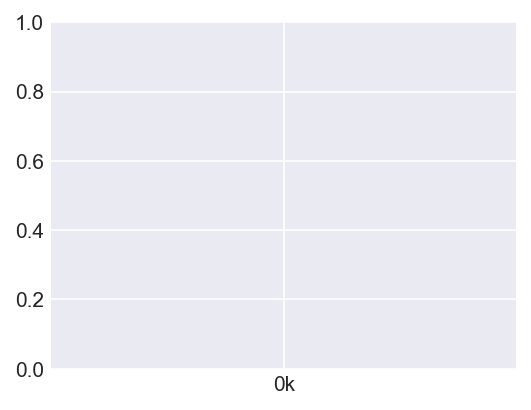

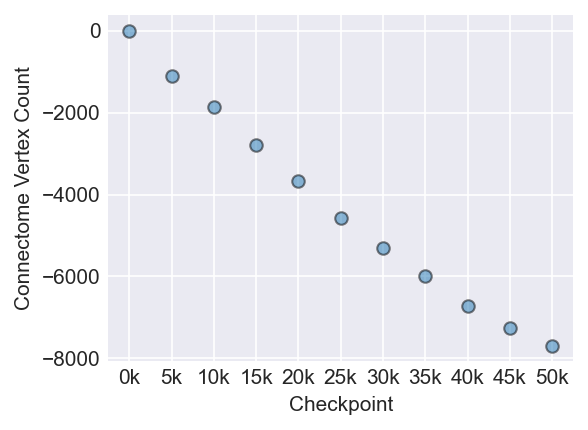

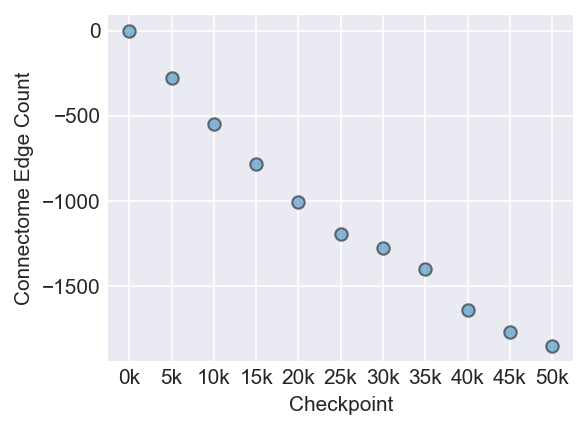

In [20]:
start_checkpoint = 0
end_checkpoint = 50
with plt.style.context("seaborn-v0_8-darkgrid"):
    plt.figure(figsize=(4,3), dpi=150)
    plt.scatter(
        [f"{i}k" for i in range(start_checkpoint, end_checkpoint+1, 5)],
        [connectome_node_counts],
        alpha=0.5,
        edgecolors="k",
    )
    plt.xlabel("Checkpoint")
    plt.ylabel("Connectome Vertex Count")

    plt.figure(figsize=(4,3), dpi=150)
    plt.scatter(
        [f"{i}k" for i in range(start_checkpoint, end_checkpoint+1, 5)],
        [connectome_edge_counts],
        alpha=0.5,
        edgecolors="k",
    )
    plt.xlabel("Checkpoint")
    plt.ylabel("Connectome Edge Count")


    plt.show()

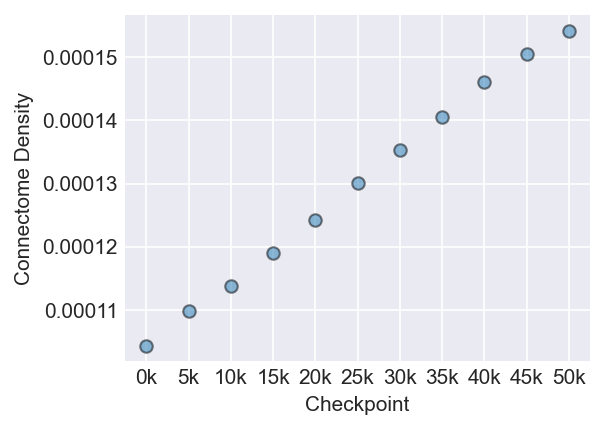

In [21]:
with plt.style.context("seaborn-v0_8-darkgrid"):
    plt.figure(figsize=(4,3), dpi=150)
    plt.scatter(
        [f"{i}k" for i in range(start_checkpoint, end_checkpoint+1, 5)],
        [nx.density(g) for g in connectomes],
        alpha=0.5,
        edgecolors="k",
    )
    plt.xlabel("Checkpoint")
    plt.ylabel("Connectome Density")
    plt.show()

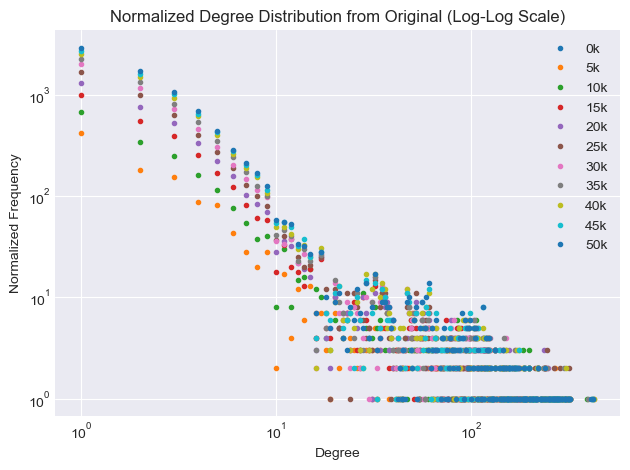

In [22]:
def create_yaxis(original_degree_freq, degree_freq):
    orig_len = len(original_degree_freq)
    new_len = len(degree_freq)
    num_to_pad = abs(orig_len - new_len)
    if orig_len > new_len:
        degree_freq = np.pad(degree_freq, (0,num_to_pad), "constant", constant_values=0)
    elif new_len > orig_len:
        original_degree_freq = np.pad(original_degree_freq, (0,num_to_pad), "constant", constant_values=0)
    return abs(original_degree_freq - degree_freq)

original_degree_freq = np.array(nx.degree_histogram(connectomes[0]))
with plt.style.context("seaborn-v0_8-darkgrid"):
    # fig, axes = plt.subplots(2, 5, figsize=(16,9))
    plt.xlabel('Degree')
    plt.ylabel('Normalized Frequency')
    plt.title('Normalized Degree Distribution from Original (Log-Log Scale)')
    for i, contactome in enumerate(connectomes):
        degree_freq = np.array(nx.degree_histogram(contactome))
        yaxis = create_yaxis(original_degree_freq, degree_freq)
        xaxis = range(len(yaxis))
        plt.loglog(xaxis, yaxis, label=f"{i*5}k", linestyle='None', marker='o', markersize="3")
        plt.legend()
        # axes[0 if i < 5 else 1, i%5].loglog(xaxis, yaxis, label=f"{i*5}k", linestyle='None', marker='o', markersize="1")
        # axes[0 if i < 5 else 1, i%5].loglog(range(len(degree_freq)), degree_freq, label=f"{i*5}k", linestyle='None', marker='o', markersize="1")
        # axes[0 if i < 5 else 1, i%5].legend()
    plt.tight_layout()
    plt.show()

In [29]:
masterEM = pd.read_csv("Master EM 1_14_26 - Sheet1 (with 50k seg ids).csv")
changes = pd.read_csv("changes.tsv", delimiter="\t", names=["change", "id1", "id2"])
changes

,change,id1,id2
0,+,667979,670152.0
1,+,670152,19219544.0
2,+,19219544,24495799.0
3,+,24495799,27250256.0
4,+,27250256,29878832.0
...,...,...,...
49995,-,8845595,8840551.0
49996,+,8845595,13974955.0
49997,+,27374055,29894423.0
49998,+,29894423,27391033.0


In [32]:
col_name = "seg_50k_id"
traced_status_df = masterEM[[col_name]].copy()
traced_status_df["edit_no_completed"] = -1

for index, row in changes.iterrows():
    # Access values from df1
    current_idx = index
    current_id1 = row['id1']
    current_id2 = row['id2']

    # Find corresponding row in df2 and update
    # This is an example, real-world logic might be more complex
    if current_id1 in traced_status_df[col_name].values:
        traced_status_df.loc[traced_status_df[col_name] == current_id1, 'edit_no_completed'] = current_idx
    if current_id2 in traced_status_df[col_name].values:
        traced_status_df.loc[traced_status_df[col_name] == current_id2, 'edit_no_completed'] = current_idx

traced_status_df = (
    traced_status_df.groupby(col_name, dropna=False)
        .agg({"edit_no_completed" : lambda s: s.max(skipna=True)})
        .reset_index()
)

traced_status_df

,seg_50k_id,edit_no_completed
0,0,-1
1,444162,31458
2,550518,16863
3,554355,16691
4,558647,-1
...,...,...
2832,51779024,43486
2833,53402525,20855
2834,53516765,48472
2835,54675565,12965


In [34]:
traced_counts = []
num_nodes = []
checkpoint_nos = [i*1000 for i in range(start_checkpoint, end_checkpoint+1, 5)]
for i, connectome in enumerate(connectomes):
    node_list = list(connectome.nodes())
    num_nodes.append(len(node_list))
    node_df = pd.DataFrame({col_name: node_list})
    node_df = node_df.merge(traced_status_df, on=col_name, how="left", validate="m:1")
    node_df = node_df[node_df['edit_no_completed'] <= checkpoint_nos[i]]
    traced_counts.append(len(node_df['edit_no_completed']))
traced_counts, num_nodes

([70, 230, 424, 641, 933, 1232, 1498, 1705, 1898, 2130, 2356],
 [41375, 40270, 39513, 38577, 37706, 36811, 36069, 35382, 34651, 34117, 33688])

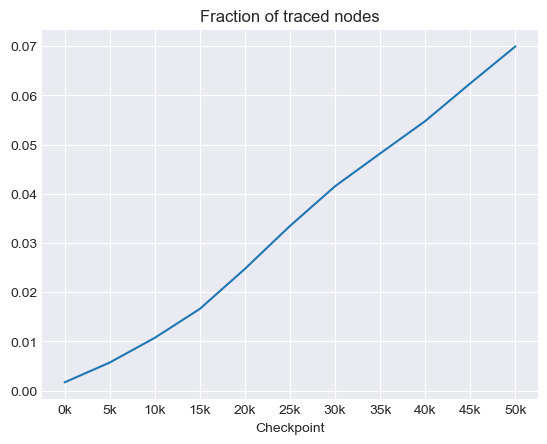

In [35]:
checkpoint_nos = [i*1000 for i in range(start_checkpoint, end_checkpoint+1, 5)],
with plt.style.context("seaborn-v0_8-darkgrid"):
    plt.xlabel('Checkpoint')
    plt.title('Fraction of traced nodes')
    plt.plot(
        [f"{i}k" for i in range(start_checkpoint, end_checkpoint+1, 5)],
        np.array(traced_counts) / np.array(num_nodes)
    )
    plt.show()

In [37]:
presynapse_completion = []
postsynapse_completion = []
both_completeness = []
either_completeness = []
num_synapses = []
checkpoint_nos = [i*1000 for i in range(start_checkpoint, end_checkpoint+1, 5)]
for i, connectome_df in enumerate(connectome_dfs):
    pre_list = list(connectome_df["pre"])
    post_list = list(connectome_df["post"])
    num_synapses.append(len(connectome_df))

    pre_df = pd.DataFrame({col_name: pre_list})
    pre_df = pre_df.merge(traced_status_df, on=col_name, how="left", validate="m:1")
    completed_pre_df = pre_df[pre_df['edit_no_completed'] <= checkpoint_nos[i]]
    presynapse_completion.append(len(completed_pre_df))

    post_df = pd.DataFrame({col_name: post_list})
    post_df = post_df.merge(traced_status_df, on=col_name, how="left", validate="m:1")
    completed_post_df = post_df[post_df['edit_no_completed'] <= checkpoint_nos[i]]
    postsynapse_completion.append(len(completed_post_df))

    pre_post_df = pd.concat([pre_df, post_df], axis=1)
    pre_post_df.columns = ["pre_id", "pre_edit_no_completed", "post_id", "post_edit_no_completed"]

    both_df = pre_post_df[(pre_post_df['pre_edit_no_completed'] <= checkpoint_nos[i]) & (pre_post_df["post_edit_no_completed"] <= checkpoint_nos[i])]
    both_completeness.append(len(both_df))

    either_df = pre_post_df[(pre_post_df['pre_edit_no_completed'] <= checkpoint_nos[i]) | (pre_post_df["post_edit_no_completed"] <= checkpoint_nos[i])]
    either_completeness.append(len(either_df))

either_completeness

[697, 8689, 17672, 26982, 36568, 43903, 49092, 56659, 63278, 71593, 77224]

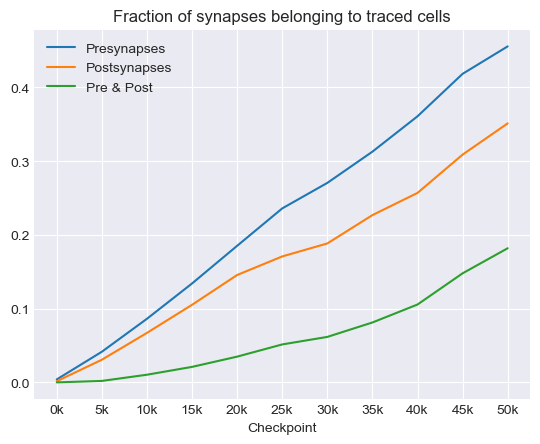

In [ ]:
checkpoint_nos = [i*1000 for i in range(start_checkpoint, end_checkpoint+1, 5)],
with plt.style.context("seaborn-v0_8-darkgrid"):
    # fig, axes = plt.subplots(2, 5, figsize=(16,9))
    plt.xlabel('Checkpoint')
    plt.title('Fraction of synapses belonging to traced cells')
    plt.plot(
        [f"{i}k" for i in range(start_checkpoint, end_checkpoint+1, 5)],
        np.array(presynapse_completion) / np.array(num_synapses),
        label="Presynapses"
    )
    plt.plot(
        [f"{i}k" for i in range(start_checkpoint, end_checkpoint+1, 5)],
        np.array(postsynapse_completion) / np.array(num_synapses),
        label="Postsynapses"
    )
    plt.plot(
        [f"{i}k" for i in range(start_checkpoint, end_checkpoint+1, 5)],
        np.array(both_completeness) / np.array(num_synapses),
        label="Pre & Post"
    )
    # plt.plot(
    #     [f"{i}k" for i in range(start_checkpoint, end_checkpoint+1, 5)],
    #     np.array(either_completeness) / np.array(num_synapses),
    #     label="Either terminal"
    # )
    plt.legend()
    plt.show()

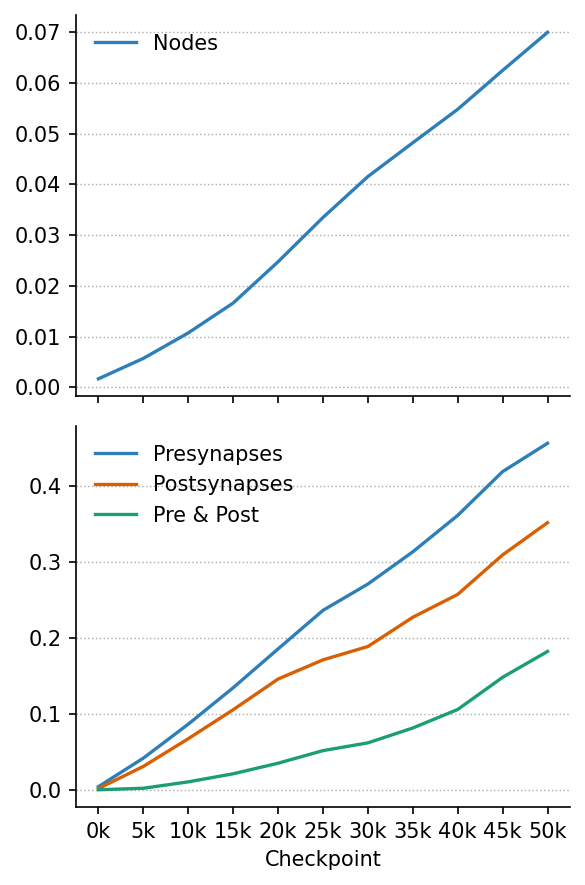

In [54]:
combined_checkpoints = [f"{i}k" for i in range(start_checkpoint, end_checkpoint+1, 5)]

plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 150

fig, axes = plt.subplots(2, 1, figsize=(4, 6))

axes[0].plot(
    combined_checkpoints,
    np.array(traced_counts) / np.array(num_nodes),
    label="Nodes",
    color='#2c7fb8',
    linewidth=1.6,
)

axes[0].set_xticklabels([])
axes[0].legend(frameon=False)
# axes[0].set_xlabel('Checkpoint')
# axes[0].set_title('Fraction of traced nodes')

axes[1].plot(
    combined_checkpoints,
    np.array(presynapse_completion) / np.array(num_synapses),
    label='Presynapses',
    color='#2c7fb8',
    linewidth=1.6,
)
axes[1].plot(
    combined_checkpoints,
    np.array(postsynapse_completion) / np.array(num_synapses),
    label='Postsynapses',
    color='#d95f02',
    linewidth=1.6,
)
axes[1].plot(
    combined_checkpoints,
    np.array(both_completeness) / np.array(num_synapses),
    label='Pre & Post',
    color='#1b9e77',
    linewidth=1.6,
)
axes[1].set_xlabel('Checkpoint')
# axes[1].set_title('Fraction of synapses belonging to traced cells')
axes[1].legend(frameon=False)

for ax in axes:
    ax.grid(True, axis='y', linestyle=':', linewidth=0.7)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.tight_layout()
plt.show()
